# 03. Dense Neural Network Experiments
**Objective:** Implement, train, and evaluate a Dense Neural Network for binary sentiment classification using the GoEmotions dataset.# 03 Dense RNN LSTM - To be implemented

In [1]:
import sys
import os
import torch
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from torch.utils.data import DataLoader, TensorDataset

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

from src.models import DenseNN
from src.train import train_model
from src.evaluate import evaluate_model, print_metrics
from src.visualize import plot_training_curves, plot_confusion_matrix

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cpu


In [2]:
train_df = pd.read_csv('../data/processed/train.csv')
test_df = pd.read_csv('../data/processed/test.csv')
label_map = {'negative': 0, 'positive': 1}
train_df['label'] = train_df['sentiment'].map(label_map)
test_df['label'] = test_df['sentiment'].map(label_map)

print(f"Train size: {len(train_df)}, Test size: {len(test_df)}")
print("\nClass distribution in Train:")
print(train_df['label'].value_counts())

Train size: 800, Test size: 200

Class distribution in Train:
label
1    400
0    400
Name: count, dtype: int64


In [3]:
#convert text to fixed-size vectors
vectorizer = CountVectorizer(max_features=5000, stop_words='english')

X_train_bow = vectorizer.fit_transform(train_df['cleaned_text']).toarray()
X_test_bow = vectorizer.transform(test_df['cleaned_text']).toarray()
y_train = train_df['label'].values
y_test = test_df['label'].values

input_dim = X_train_bow.shape[1]
print(f"Input dimension (Vocabulary size): {input_dim}")

Input dimension (Vocabulary size): 2253


In [4]:
X_train_tensor = torch.FloatTensor(X_train_bow)
y_train_tensor = torch.FloatTensor(y_train)
X_test_tensor = torch.FloatTensor(X_test_bow)
y_test_tensor = torch.FloatTensor(y_test)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

C:\Users\Krystal\AppData\Local\Temp\ipykernel_16004\3309958125.py:2: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:214.)
  y_train_tensor = torch.FloatTensor(y_train)


In [5]:
from torch.utils.data import Dataset

class SentimentDataset(Dataset):

    def __init__(self, features: np.ndarray, labels: np.ndarray):
        self.features = torch.FloatTensor(features.copy())
        self.labels = torch.FloatTensor(labels.copy())

    def __len__(self):
        return len(self.features)

    def __getitem__(self, idx):
        return {
            "input_ids": self.features[idx],
            "labels": self.labels[idx]
        }

train_dataset = SentimentDataset(X_train_bow, y_train)
test_dataset = SentimentDataset(X_test_bow, y_test)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

print("DataLoaders created successfully!!!")

DataLoaders created successfully!!!


In [6]:
model_dense = DenseNN(
    input_dim=input_dim,
    hidden_dims=[256, 128],
    output_dim=1,
    dropout_rate=0.3
).to(device)

print("Training...")
history_dense = train_model(
    model=model_dense,
    train_loader=train_loader,
    val_loader=test_loader,
    epochs=20,
    lr=0.001,
    patience=4,
    device=device
)
print(" training completed!!")

Training...
 training completed!!


In [7]:
metrics_dense = evaluate_model(model_dense, test_loader, device=device)
print_metrics(metrics_dense, model_name="DenseNN (BoW)")


 Evaluation Metrics - DenseNN (BoW)
  Accuracy : 0.7350
  Precision: 0.7374
  Recall   : 0.7300
  F1-score : 0.7337
  Kappa    : 0.4700
  Confusion Matrix:
    [74, 26]
    [27, 73]



Figure saved to: ../outputs/figures/dense_training_curves.png


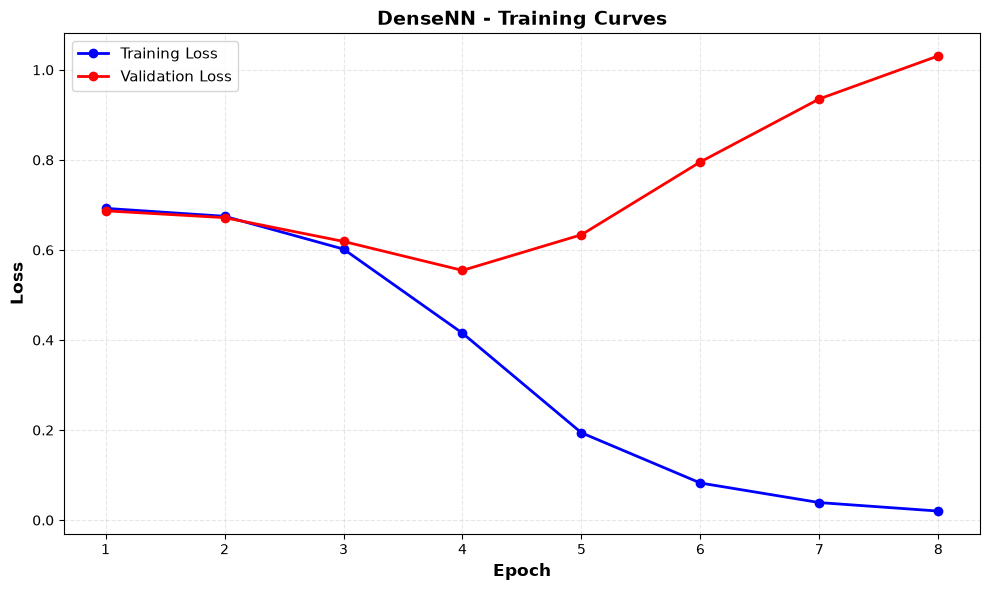

Figure saved to: ../outputs/figures/dense_confusion_matrix.png


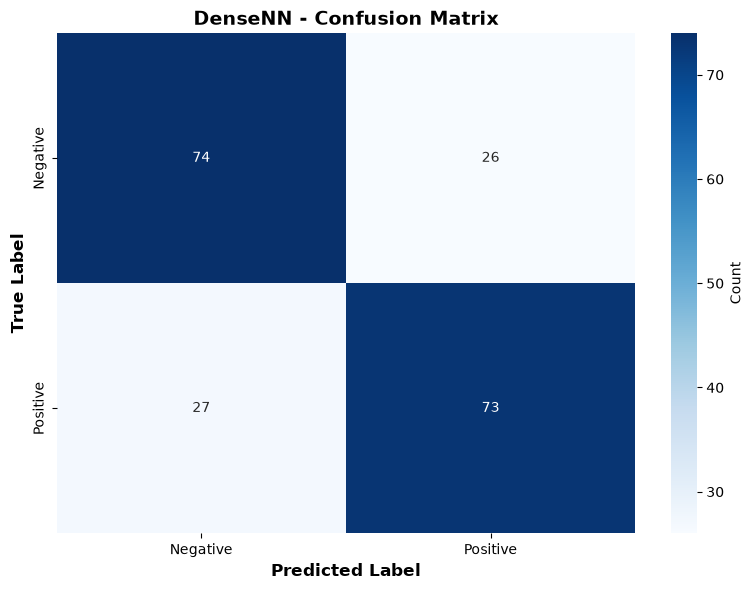

In [8]:
#save training curves
plot_training_curves(
    train_losses=history_dense['train_losses'],
    val_losses=history_dense['val_losses'],
    model_name="DenseNN",
    save_path="../outputs/figures/dense_training_curves.png",
    show=True
)

#save confusion matrix
plot_confusion_matrix(
    confusion_matrix=np.array(metrics_dense['confusion_matrix']),
    class_names=["Negative", "Positive"],
    model_name="DenseNN",
    save_path="../outputs/figures/dense_confusion_matrix.png",
    show=True
)

## 2. Recurrent Models: Vanilla RNN and LSTM
Unlike the Dense NN, recurrent models process text as sequences of tokens. We will map words to indices using the vocabulary built previously.

In [9]:
MAX_SEQ_LEN = 30

#reuse vocabulary from CountVectorizer
word2idx = {word: idx + 1 for word, idx in vectorizer.vocabulary_.items()}
PAD_IDX = 0
vocab_size = len(word2idx) + 1

def text_to_sequence(text, max_len=MAX_SEQ_LEN):
    tokens = text.split()
    seq = [word2idx.get(t, PAD_IDX) for t in tokens] # PAD_IDX for Out-Of-Vocabulary words
    if len(seq) < max_len:
        seq = [PAD_IDX] * (max_len - len(seq)) + seq # Left padding
    else:
        seq = seq[:max_len]
    return seq

X_train_seq = [text_to_sequence(text) for text in train_df['cleaned_text']]
X_test_seq = [text_to_sequence(text) for text in test_df['cleaned_text']]
print(f"Vocabulary size: {vocab_size}")
print(f"Sample sequence length: {len(X_train_seq[0])}")

Vocabulary size: 2254
Sample sequence length: 30


In [10]:
from torch.utils.data import Dataset

class SequenceDataset(Dataset):
    def __init__(self, sequences, labels):
        self.sequences = sequences
        self.labels = labels.copy()

    def __len__(self):
        return len(self.sequences)
    def __getitem__(self, idx):
        return {
            "input_ids": torch.tensor(self.sequences[idx], dtype=torch.long),
            "labels": torch.tensor(self.labels[idx], dtype=torch.float)
        }

train_seq_dataset = SequenceDataset(X_train_seq, y_train)
test_seq_dataset = SequenceDataset(X_test_seq, y_test)

train_seq_loader = DataLoader(train_seq_dataset, batch_size=64, shuffle=True)
test_seq_loader = DataLoader(test_seq_dataset, batch_size=64, shuffle=False)

print("Sequence DataLoaders created successfully!")

Sequence DataLoaders created successfully!


Training Vanilla RNN...
Vanila RNN training completed!!

 Evaluation Metrics - Vanilla RNN
  Accuracy : 0.4950
  Precision: 0.4923
  Recall   : 0.3200
  F1-score : 0.3879
  Kappa    : -0.0100
  Confusion Matrix:
    [67, 33]
    [68, 32]

Figure saved to: ../outputs/figures/rnn_training_curves.png


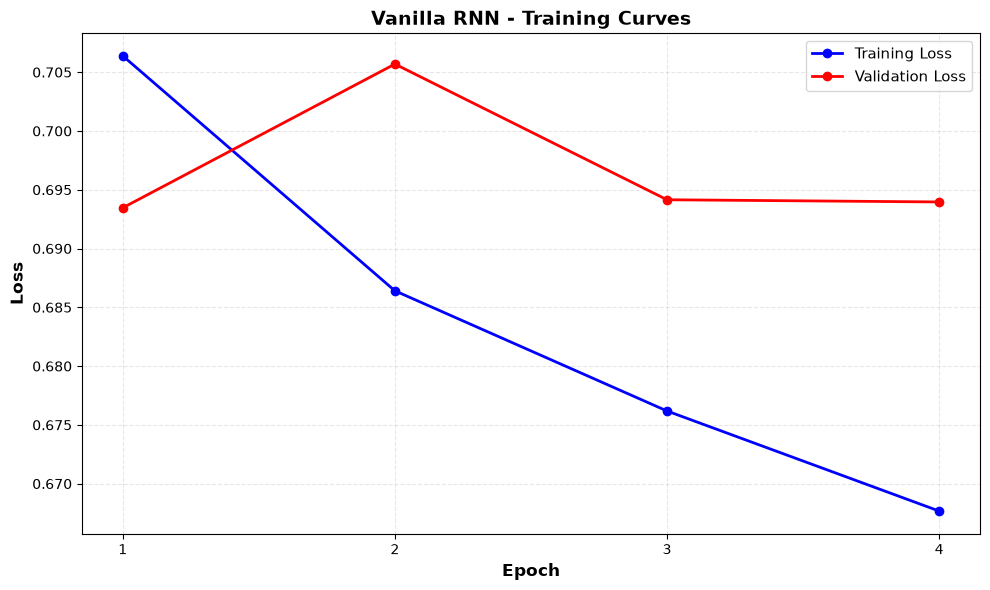

Figure saved to: ../outputs/figures/rnn_confusion_matrix.png


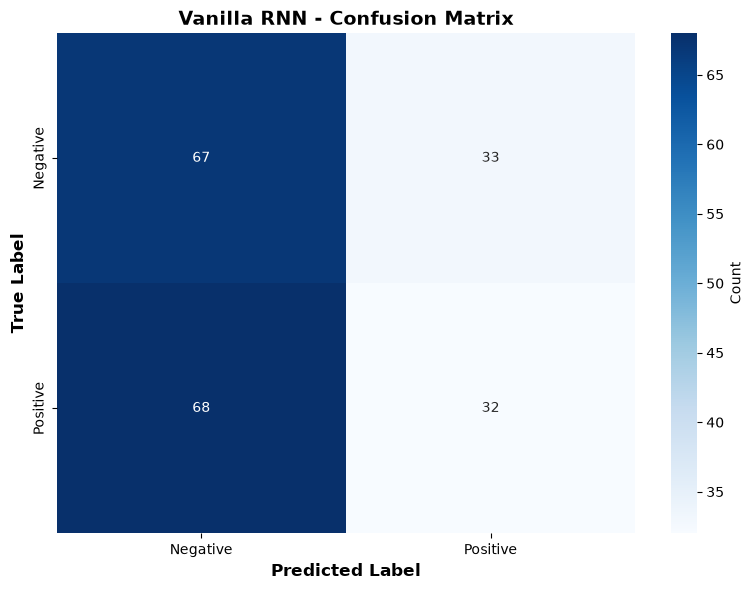

In [11]:
from src.models import VanillaRNN

model_rnn = VanillaRNN(
    vocab_size=vocab_size,
    embedding_dim=64,
    hidden_dim=128,
    output_dim=1,
    num_layers=1,
    bidirectional=True,
    dropout_rate=0.3
).to(device)

print("Training Vanilla RNN...")
history_rnn = train_model(
    model=model_rnn,
    train_loader=train_seq_loader,
    val_loader=test_seq_loader,
    epochs=15,
    lr=0.001,
    patience=3,
    device=device
)
print("Vanila RNN training completed!!")

metrics_rnn = evaluate_model(model_rnn, test_seq_loader, device=device)
print_metrics(metrics_rnn, model_name="Vanilla RNN")

plot_training_curves(history_rnn['train_losses'], history_rnn['val_losses'], "Vanilla RNN", "../outputs/figures/rnn_training_curves.png")
plot_confusion_matrix(np.array(metrics_rnn['confusion_matrix']), ["Negative", "Positive"], "Vanilla RNN", "../outputs/figures/rnn_confusion_matrix.png")

Training LSTM...
LSTM training completed!

 Evaluation Metrics - LSTM
  Accuracy : 0.6300
  Precision: 0.6121
  Recall   : 0.7100
  F1-score : 0.6574
  Kappa    : 0.2600
  Confusion Matrix:
    [55, 45]
    [29, 71]

Figure saved to: ../outputs/figures/lstm_training_curves.png


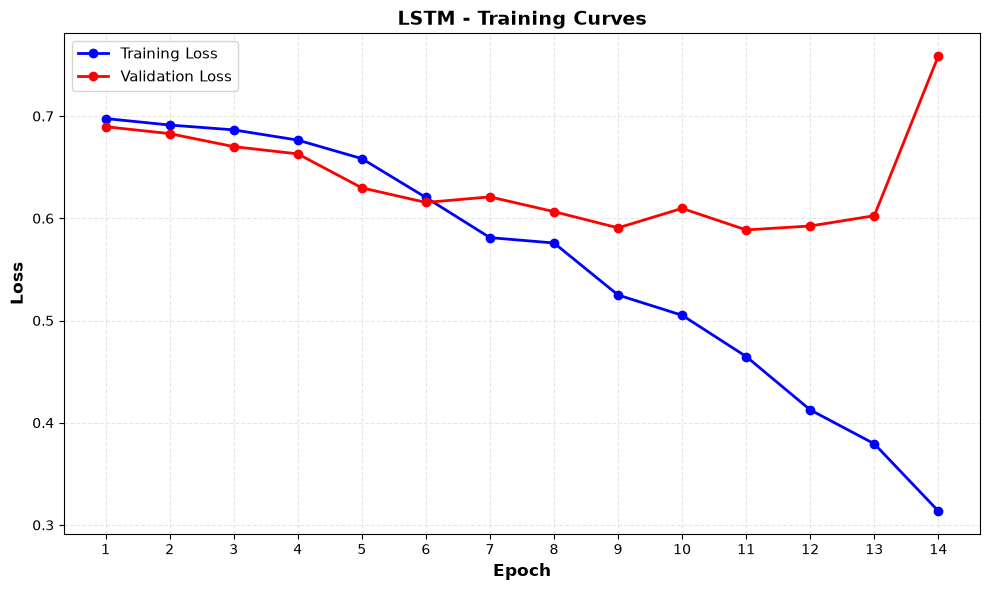

Figure saved to: ../outputs/figures/lstm_confusion_matrix.png


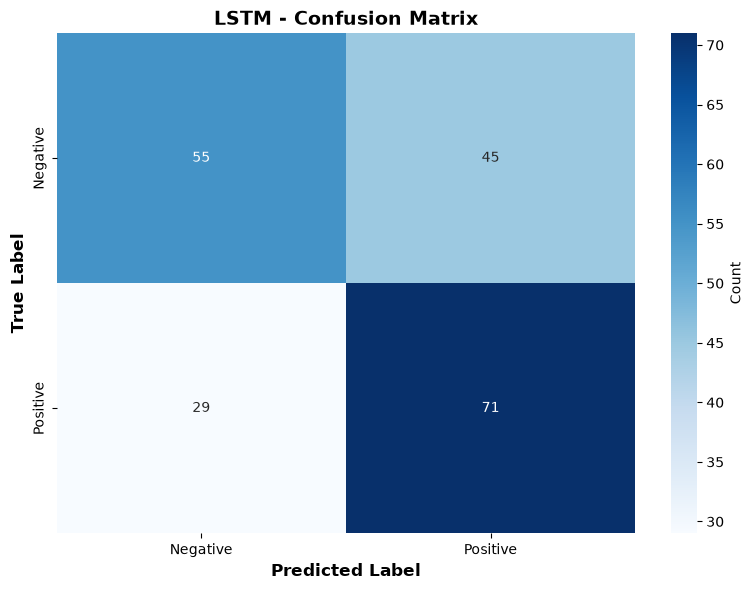

In [12]:
from src.models import LSTMClassifier

model_lstm = LSTMClassifier(
    vocab_size=vocab_size,
    embedding_dim=64,
    hidden_dim=128,
    output_dim=1,
    num_layers=2,
    bidirectional=True,
    dropout_rate=0.3
).to(device)

print("Training LSTM...")
history_lstm = train_model(
    model=model_lstm,
    train_loader=train_seq_loader,
    val_loader=test_seq_loader,
    epochs=15,
    lr=0.001,
    patience=3,
    device=device
)
print("LSTM training completed!")

metrics_lstm = evaluate_model(model_lstm, test_seq_loader, device=device)
print_metrics(metrics_lstm, model_name="LSTM")

plot_training_curves(history_lstm['train_losses'], history_lstm['val_losses'], "LSTM", "../outputs/figures/lstm_training_curves.png")
plot_confusion_matrix(np.array(metrics_lstm['confusion_matrix']), ["Negative", "Positive"], "LSTM", "../outputs/figures/lstm_confusion_matrix.png")

Figure saved to: ../outputs/figures/comp_accuracy.png


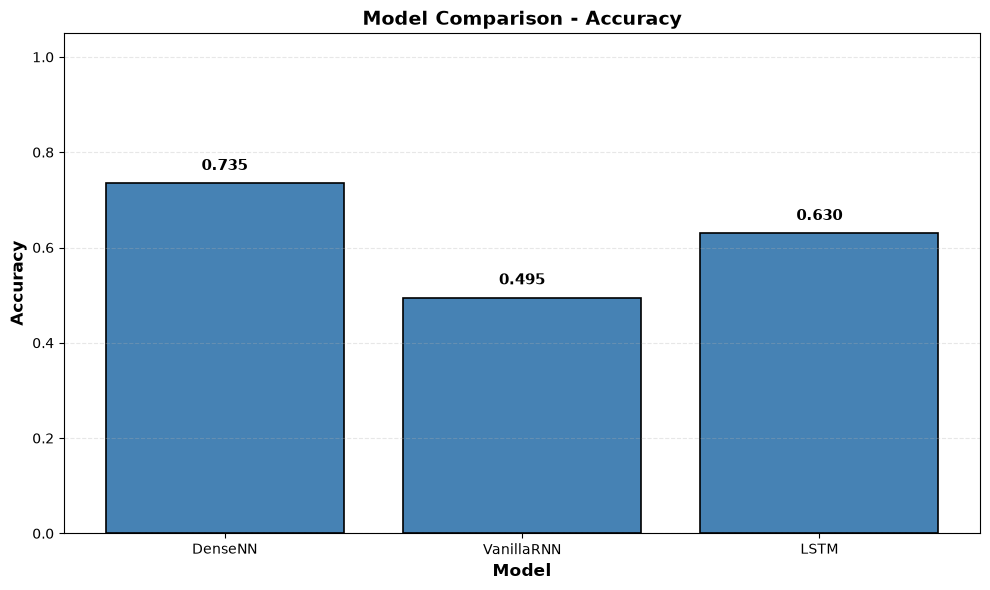

Figure saved to: ../outputs/figures/comp_f1.png


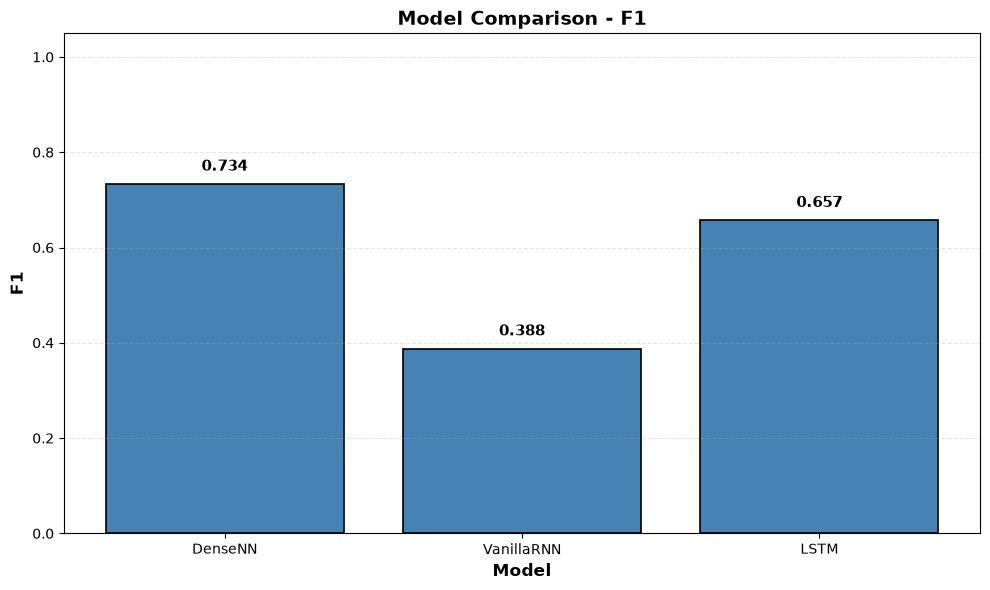

Figure saved to: ../outputs/figures/comp_kappa.png


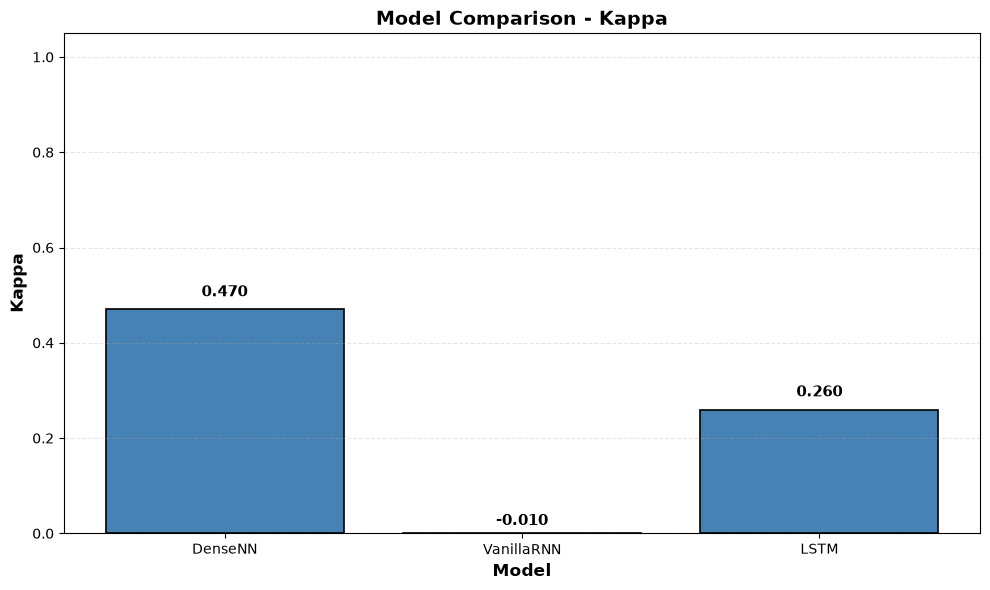

All experiments finished! Check the outputs/figures/ directory.


In [13]:
from src.visualize import plot_model_comparison

all_metrics = {
    "DenseNN": metrics_dense,
    "VanillaRNN": metrics_rnn,
    "LSTM": metrics_lstm
}

plot_model_comparison(all_metrics, "accuracy", "../outputs/figures/comp_accuracy.png")
plot_model_comparison(all_metrics, "f1", "../outputs/figures/comp_f1.png")
plot_model_comparison(all_metrics, "kappa", "../outputs/figures/comp_kappa.png")

print("All experiments finished! Check the outputs/figures/ directory.")